          feature set          model        mae       rmse        r2  \
0       clinical-only         linear   9.871309  13.380188  0.268337   
1       clinical-only          ridge   9.809911  13.270929  0.280237   
2       clinical-only          lasso   9.900222  13.315871  0.275354   
3       clinical-only  random forest  10.457944  14.214915  0.174199   
4  clinical + genetic         linear   8.560218  11.851907  0.425932   
5  clinical + genetic          ridge   8.517166  11.741496  0.436578   
6  clinical + genetic          lasso   8.679460  11.938084  0.417553   
7  clinical + genetic  random forest   9.188296  12.595969  0.351589   

   within20%  
0  37.974684  
1  38.245931  
2  37.341772  
3  36.437613  
4  44.122966  
5  44.213382  
6  44.303797  
7  42.585895  
           feature set          model    dose group    n        mae       rmse
0        clinical-only         linear           low  377   9.603926  12.107726
1        clinical-only         linear  intermediate  590  

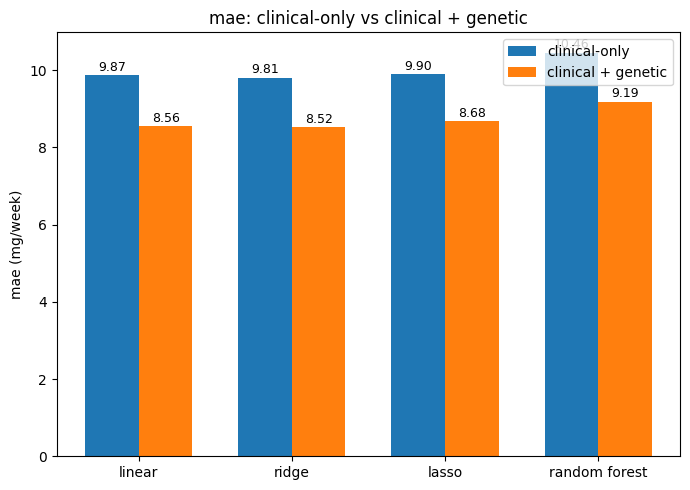

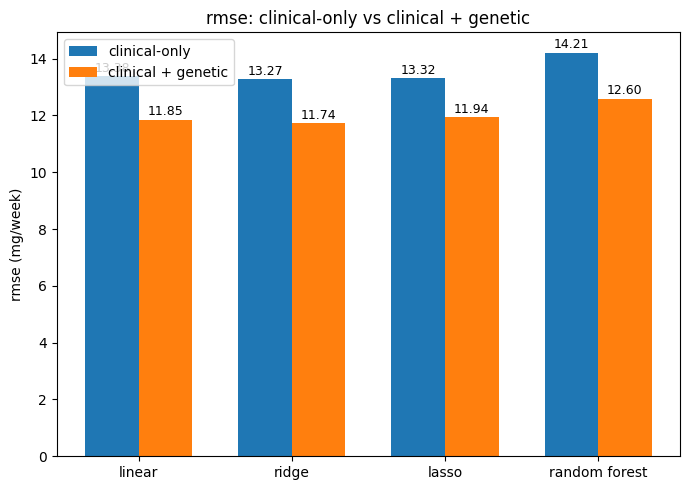

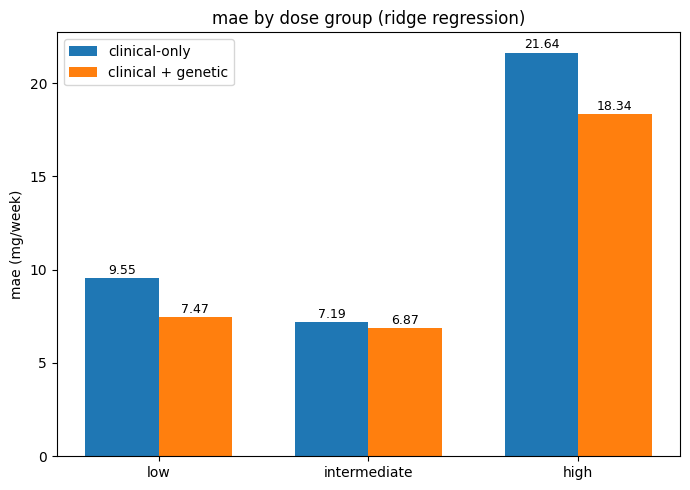

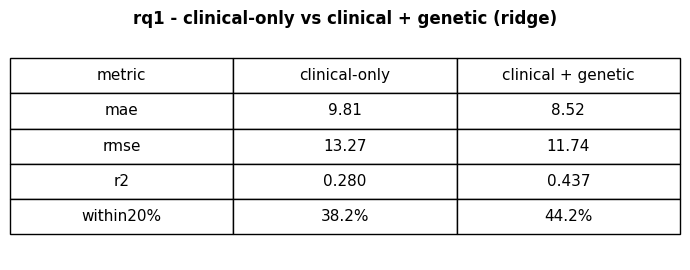

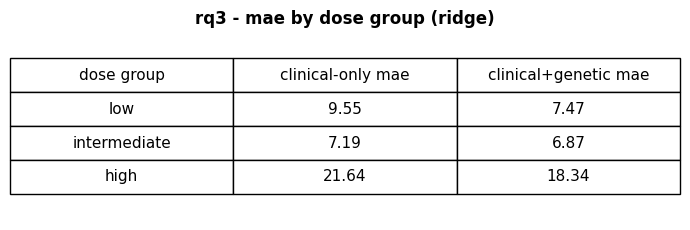

saved to: C:\Users\HP\desktop\results\figures


In [2]:
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

df = pd.read_csv("IWPS.csv")
df = df.drop(columns=df.columns[df.isna().all()])

target = "Therapeutic Dose of Warfarin"
df["dose"] = pd.to_numeric(df[target], errors="coerce")
df_model = df[df["dose"] > 0].copy()
y = df_model["dose"]

clinical_features = ["Gender", "Race (Reported)", "Age", "Height (cm)", "Weight (kg)",
    "Indication for Warfarin Treatment", "Diabetes",
    "Congestive Heart Failure and/or Cardiomyopathy", "Valve Replacement",
    "Target INR", "Current Smoker", "Amiodarone (Cordarone)",
    "Carbamazepine (Tegretol)", "Phenytoin (Dilantin)", "Rifampin or Rifampicin"]

genetic_features = ["Cyp2C9 genotypes", "VKORC1 -1639 consensus"]

x_clinical = df_model[clinical_features].copy()
x_genetic = df_model[clinical_features + genetic_features].copy()

cat_cols = [c for c in clinical_features + genetic_features if c not in ["Height (cm)", "Weight (kg)"]]
for x in [x_clinical, x_genetic]:
    for col in x.columns:
        if col in cat_cols:
            x[col] = x[col].apply(lambda v: str(v) if pd.notna(v) else np.nan)

train_idx, test_idx = train_test_split(x_clinical.index, test_size=0.2, random_state=42)
x_clinical_train, x_clinical_test = x_clinical.loc[train_idx], x_clinical.loc[test_idx]
x_genetic_train, x_genetic_test = x_genetic.loc[train_idx], x_genetic.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

numeric_features = ["Height (cm)", "Weight (kg)"]
num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
cat_pipe = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="unknown")), ("encode", OneHotEncoder(handle_unknown="ignore"))])

cat_clinical = [c for c in clinical_features if c not in numeric_features]
cat_genetic = cat_clinical + genetic_features

preprocessor_clinical = ColumnTransformer([("num", num_pipe, numeric_features), ("cat", cat_pipe, cat_clinical)])
preprocessor_genetic = ColumnTransformer([("num", num_pipe, numeric_features), ("cat", cat_pipe, cat_genetic)])

models = {
    "linear": LinearRegression(),
    "ridge": Ridge(alpha=1.0),
    "lasso": Lasso(alpha=0.1),
    "random forest": RandomForestRegressor(n_estimators=200, random_state=42)
}

results = []
fitted_pipes = {}

def run_models(preprocessor, x_train, x_test, label):
    for name, model in models.items():
        pipe = Pipeline([("prep", preprocessor), ("model", model)])
        pipe.fit(x_train, y_train)
        preds = pipe.predict(x_test)
        mae = mean_absolute_error(y_test, preds)
        rmse = np.sqrt(mean_squared_error(y_test, preds))
        r2 = r2_score(y_test, preds)
        within20 = ((preds >= 0.8 * y_test) & (preds <= 1.2 * y_test)).mean() * 100
        results.append({"feature set": label, "model": name, "mae": mae, "rmse": rmse, "r2": r2, "within20%": within20})
        fitted_pipes[(label, name)] = (pipe, preds)

run_models(preprocessor_clinical, x_clinical_train, x_clinical_test, "clinical-only")
run_models(preprocessor_genetic, x_genetic_train, x_genetic_test, "clinical + genetic")
results_df = pd.DataFrame(results)
print(results_df)

def dose_group(dose):
    if dose <= 21:
        return "low"
    elif dose < 49:
        return "intermediate"
    else:
        return "high"

groups = y_test.apply(dose_group)
group_results = []
for (label, name), (pipe, preds) in fitted_pipes.items():
    for g in ["low", "intermediate", "high"]:
        mask = groups == g
        if mask.sum() == 0:
            continue
        mae_g = mean_absolute_error(y_test[mask], preds[mask])
        rmse_g = np.sqrt(mean_squared_error(y_test[mask], preds[mask]))
        group_results.append({"feature set": label, "model": name, "dose group": g, "n": mask.sum(), "mae": mae_g, "rmse": rmse_g})

group_results_df = pd.DataFrame(group_results)
print(group_results_df)

save_dir = os.path.join(os.path.expanduser("~"), "desktop", "results", "figures")
os.makedirs(save_dir, exist_ok=True)

def add_labels(bars, ax):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.2f}", xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)

model_names = ["linear", "ridge", "lasso", "random forest"]
x = np.arange(len(model_names))
width = 0.35

def get_vals(d, col):
    clinical = d[d["feature set"] == "clinical-only"].set_index("model").loc[model_names, col]
    genetic = d[d["feature set"] == "clinical + genetic"].set_index("model").loc[model_names, col]
    return clinical.values, genetic.values

for metric, ylabel, fname in [("mae", "mae (mg/week)", "mae_comparison.png"), ("rmse", "rmse (mg/week)", "rmse_comparison.png")]:
    clinical_vals, genetic_vals = get_vals(results_df, metric)
    fig, ax = plt.subplots(figsize=(7, 5))
    b1 = ax.bar(x - width/2, clinical_vals, width, label="clinical-only")
    b2 = ax.bar(x + width/2, genetic_vals, width, label="clinical + genetic")
    ax.set_ylabel(ylabel)
    ax.set_title(f"{metric}: clinical-only vs clinical + genetic")
    ax.set_xticks(x)
    ax.set_xticklabels(model_names)
    ax.legend()
    add_labels(b1, ax)
    add_labels(b2, ax)
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, fname), dpi=300)
    plt.show()

ridge_g = group_results_df[group_results_df["model"] == "ridge"]
dose_groups = ["low", "intermediate", "high"]
clinical_g = ridge_g[ridge_g["feature set"] == "clinical-only"].set_index("dose group").loc[dose_groups, "mae"]
genetic_g = ridge_g[ridge_g["feature set"] == "clinical + genetic"].set_index("dose group").loc[dose_groups, "mae"]

x2 = np.arange(len(dose_groups))
fig, ax = plt.subplots(figsize=(7, 5))
b1 = ax.bar(x2 - width/2, clinical_g.values, width, label="clinical-only")
b2 = ax.bar(x2 + width/2, genetic_g.values, width, label="clinical + genetic")
ax.set_ylabel("mae (mg/week)")
ax.set_title("mae by dose group (ridge regression)")
ax.set_xticks(x2)
ax.set_xticklabels(dose_groups)
ax.legend()
add_labels(b1, ax)
add_labels(b2, ax)
plt.tight_layout()
plt.savefig(os.path.join(save_dir, "dose_group_comparison.png"), dpi=300)
plt.show()

ridge_overall = results_df[results_df["model"] == "ridge"].set_index("feature set")
rq1_rows = [
    ["mae", f"{ridge_overall.loc['clinical-only','mae']:.2f}", f"{ridge_overall.loc['clinical + genetic','mae']:.2f}"],
    ["rmse", f"{ridge_overall.loc['clinical-only','rmse']:.2f}", f"{ridge_overall.loc['clinical + genetic','rmse']:.2f}"],
    ["r2", f"{ridge_overall.loc['clinical-only','r2']:.3f}", f"{ridge_overall.loc['clinical + genetic','r2']:.3f}"],
    ["within20%", f"{ridge_overall.loc['clinical-only','within20%']:.1f}%", f"{ridge_overall.loc['clinical + genetic','within20%']:.1f}%"],
]
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.axis("off")
ax.set_title("rq1 - clinical-only vs clinical + genetic (ridge)", fontweight="bold")
tbl = ax.table(cellText=rq1_rows, colLabels=["metric", "clinical-only", "clinical + genetic"], loc="center", cellLoc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.scale(1, 2)
plt.tight_layout()
plt.savefig(os.path.join(save_dir, "rq1_summary_table.png"), dpi=300, bbox_inches="tight")
plt.show()

rq3_rows = [[g, f"{clinical_g[g]:.2f}", f"{genetic_g[g]:.2f}"] for g in dose_groups]
fig, ax = plt.subplots(figsize=(7, 2.4))
ax.axis("off")
ax.set_title("rq3 - mae by dose group (ridge)", fontweight="bold")
tbl2 = ax.table(cellText=rq3_rows, colLabels=["dose group", "clinical-only mae", "clinical+genetic mae"], loc="center", cellLoc="center")
tbl2.auto_set_font_size(False)
tbl2.set_fontsize(11)
tbl2.scale(1, 2)
plt.tight_layout()
plt.savefig(os.path.join(save_dir, "rq3_dose_group_table.png"), dpi=300, bbox_inches="tight")
plt.show()

print("saved to:", save_dir)

In [3]:
from sklearn.model_selection import GridSearchCV

ridge_grid = {"model__alpha": [0.01, 0.1, 1, 10, 100]}
lasso_grid = {"model__alpha": [0.001, 0.01, 0.1, 1, 10]}
rf_grid = {"model__n_estimators": [100, 200, 400], "model__max_depth": [None, 10, 20], "model__min_samples_leaf": [1, 5, 10]}

In [5]:


def tune_models(preprocessor, x_train, y_train):
    tuned = {"linear": LinearRegression()}
    for name, base_model, grid in [("ridge", Ridge(), ridge_grid), ("lasso", Lasso(max_iter=20000), lasso_grid), ("random forest", RandomForestRegressor(random_state=42), rf_grid)]:
        pipe = Pipeline([("prep", preprocessor), ("model", base_model)])
        search = GridSearchCV(pipe, grid, cv=5, scoring="neg_mean_absolute_error")
        search.fit(x_train, y_train)
        tuned[name] = search.best_estimator_.named_steps["model"]
    return tuned

models_clinical = tune_models(preprocessor_clinical, x_clinical_train, y_train)
models_genetic = tune_models(preprocessor_genetic, x_genetic_train, y_train)

In [6]:


tuned_results = []

def run_tuned_models(preprocessor, x_train, x_test, label, model_dict):
    for name, model in model_dict.items():
        pipe = Pipeline([("prep", preprocessor), ("model", model)])
        pipe.fit(x_train, y_train)
        preds = pipe.predict(x_test)
        mae = mean_absolute_error(y_test, preds)
        rmse = np.sqrt(mean_squared_error(y_test, preds))
        r2 = r2_score(y_test, preds)
        within20 = ((preds >= 0.8 * y_test) & (preds <= 1.2 * y_test)).mean() * 100
        tuned_results.append({"feature set": label, "model": name, "mae": mae, "rmse": rmse, "r2": r2, "within20%": within20})

run_tuned_models(preprocessor_clinical, x_clinical_train, x_clinical_test, "clinical-only", models_clinical)
run_tuned_models(preprocessor_genetic, x_genetic_train, x_genetic_test, "clinical + genetic", models_genetic)

tuned_results_df = pd.DataFrame(tuned_results)
print(tuned_results_df)

          feature set          model       mae       rmse        r2  within20%
0       clinical-only         linear  9.871309  13.380188  0.268337  37.974684
1       clinical-only          ridge  9.745522  13.144355  0.293901  38.155515
2       clinical-only          lasso  9.748970  13.200273  0.287881  39.059675
3       clinical-only  random forest  9.852274  13.280912  0.279154  38.155515
4  clinical + genetic         linear  8.560218  11.851907  0.425932  44.122966
5  clinical + genetic          ridge  8.467435  11.621564  0.448029  45.117541
6  clinical + genetic          lasso  8.484325  11.710939  0.439507  44.755877
7  clinical + genetic  random forest  8.775796  12.116514  0.400012  43.490054


In [7]:
counts = {}
for col in cat_clinical:
    counts[col] = x_clinical[col].nunique()
for col in genetic_features:
    counts[col] = x_genetic[col].nunique()

counts_df = pd.DataFrame(list(counts.items()), columns=["column", "unique values"]).sort_values("unique values", ascending=False)
print(counts_df)

                                            column  unique values
3                Indication for Warfarin Treatment             52
1                                  Race (Reported)             19
7                                       Target INR             12
13                                Cyp2C9 genotypes             11
2                                              Age              9
14                          VKORC1 -1639 consensus              3
0                                           Gender              2
6                                Valve Replacement              2
5   Congestive Heart Failure and/or Cardiomyopathy              2
4                                         Diabetes              2
8                                   Current Smoker              2
10                        Carbamazepine (Tegretol)              2
9                           Amiodarone (Cordarone)              2
12                          Rifampin or Rifampicin              2
11        

In [7]:
print('models_clinical' in globals())
print('preprocessor_clinical' in globals())
print('tune_models' in globals())

False
True
False


In [8]:
from sklearn.model_selection import GridSearchCV

ridge_grid = {"model__alpha": [0.01, 0.1, 1, 10, 100]}
lasso_grid = {"model__alpha": [0.001, 0.01, 0.1, 1, 10]}
rf_grid = {"model__n_estimators": [100, 200, 400], "model__max_depth": [None, 10, 20], "model__min_samples_leaf": [1, 5, 10]}

def tune_models(preprocessor, x_train, y_train):
    tuned = {"linear": LinearRegression()}
    for name, base_model, grid in [("ridge", Ridge(), ridge_grid),
                                   ("lasso", Lasso(max_iter=20000), lasso_grid),
                                   ("random forest", RandomForestRegressor(random_state=42), rf_grid)]:
        pipe = Pipeline([("prep", preprocessor), ("model", base_model)])
        search = GridSearchCV(pipe, grid, cv=5, scoring="neg_mean_absolute_error")
        search.fit(x_train, y_train)
        tuned[name] = search.best_estimator_.named_steps["model"]
    return tuned

models_clinical = tune_models(preprocessor_clinical, x_clinical_train, y_train)
models_genetic = tune_models(preprocessor_genetic, x_genetic_train, y_train)

print(models_clinical.keys())
print(models_genetic.keys())

dict_keys(['linear', 'ridge', 'lasso', 'random forest'])
dict_keys(['linear', 'ridge', 'lasso', 'random forest'])


          feature set          model       mae       rmse        r2  within20%
0       clinical-only         linear  9.871309  13.380188  0.268337  37.974684
1       clinical-only          ridge  9.745522  13.144355  0.293901  38.155515
2       clinical-only          lasso  9.748970  13.200273  0.287881  39.059675
3       clinical-only  random forest  9.852274  13.280912  0.279154  38.155515
4  clinical + genetic         linear  8.560218  11.851907  0.425932  44.122966
5  clinical + genetic          ridge  8.467435  11.621564  0.448029  45.117541
6  clinical + genetic          lasso  8.484325  11.710939  0.439507  44.755877
7  clinical + genetic  random forest  8.775796  12.116514  0.400012  43.490054

clinical-only: ridge alpha=10, lasso alpha=0.01, rf n_estimators=400, max_depth=10, min_samples_leaf=10

clinical + genetic: ridge alpha=10, lasso alpha=0.01, rf n_estimators=400, max_depth=10, min_samples_leaf=5
           feature set          model    dose group    n        mae       r

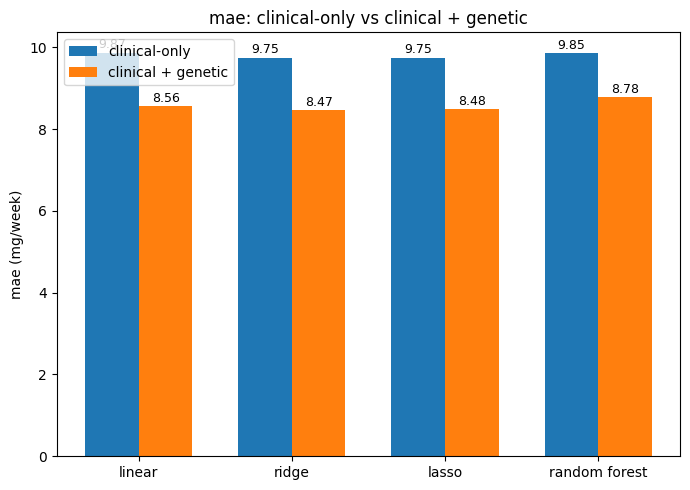

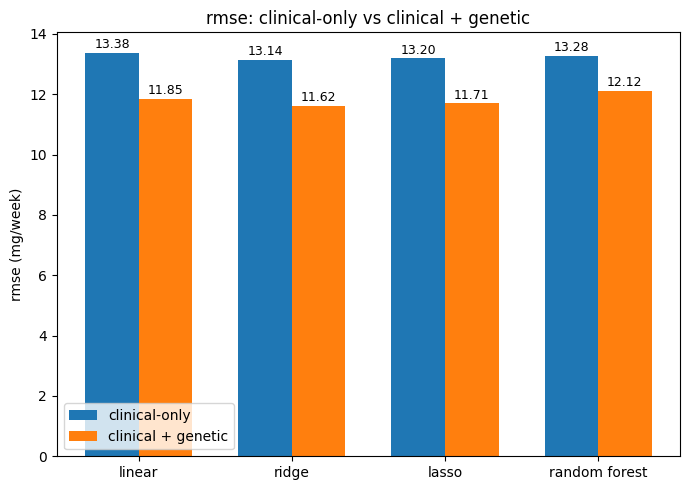

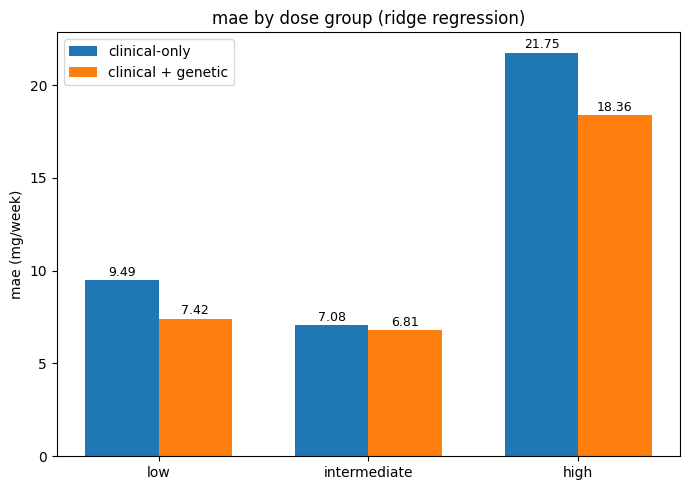

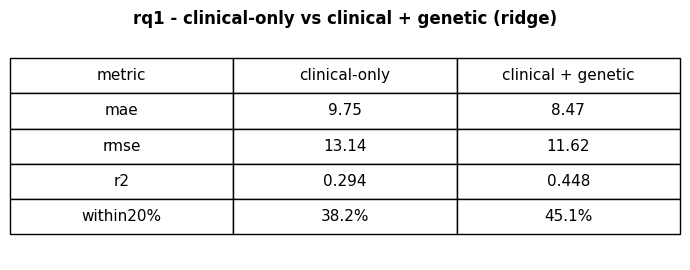

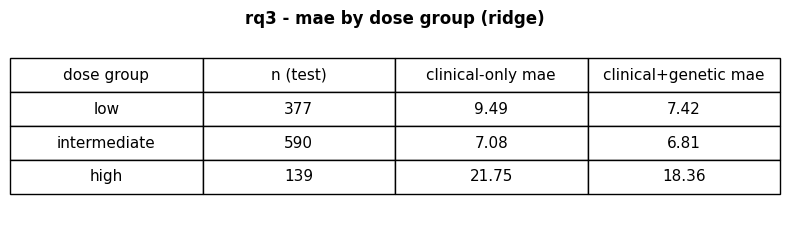

saved to: C:\Users\HP\desktop\results\figures\final


In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

final_dir = os.path.join(os.path.expanduser("~"), "desktop", "results", "figures", "final")
os.makedirs(final_dir, exist_ok=True)

model_names = ["linear", "ridge", "lasso", "random forest"]
dose_groups = ["low", "intermediate", "high"]
FS_C, FS_G = "clinical-only", "clinical + genetic"

# ---------- 1. Tuned models: predictions store karo ----------
tuned_pipes = {}      # function ke upar declare
tuned_results = []

def run_tuned_models(preprocessor, x_train, x_test, label, model_dict):
    for name, model in model_dict.items():
        pipe = Pipeline([("prep", preprocessor), ("model", model)])
        pipe.fit(x_train, y_train)
        preds = pipe.predict(x_test)
        tuned_results.append({
            "feature set": label, "model": name,
            "mae": mean_absolute_error(y_test, preds),
            "rmse": np.sqrt(mean_squared_error(y_test, preds)),
            "r2": r2_score(y_test, preds),
            "within20%": ((preds >= 0.8 * y_test) & (preds <= 1.2 * y_test)).mean() * 100})
        tuned_pipes[(label, name)] = (pipe, preds)   # nayi line

run_tuned_models(preprocessor_clinical, x_clinical_train, x_clinical_test, FS_C, models_clinical)
run_tuned_models(preprocessor_genetic, x_genetic_train, x_genetic_test, FS_G, models_genetic)
tuned_results_df = pd.DataFrame(tuned_results)
print(tuned_results_df)

# chosen hyperparameters (methods / supplementary ke liye)
for label, md in [(FS_C, models_clinical), (FS_G, models_genetic)]:
    rf = md["random forest"]
    print(f"\n{label}: ridge alpha={md['ridge'].alpha}, lasso alpha={md['lasso'].alpha}, "
          f"rf n_estimators={rf.n_estimators}, max_depth={rf.max_depth}, min_samples_leaf={rf.min_samples_leaf}")

# ---------- 2. Tuned dose-group analysis ----------
def dose_group(dose):
    if dose <= 21:
        return "low"
    elif dose < 49:
        return "intermediate"
    else:
        return "high"

groups = y_test.apply(dose_group)
tuned_group_results = []

for (label, name), (pipe, preds) in tuned_pipes.items():
    for g in dose_groups:
        mask = groups == g
        if mask.sum() == 0:
            continue
        mae_g = mean_absolute_error(y_test[mask], preds[mask])
        rmse_g = np.sqrt(mean_squared_error(y_test[mask], preds[mask]))
        tuned_group_results.append({
            "feature set": label, "model": name, "dose group": g,
            "n": mask.sum(), "mae": mae_g, "rmse": rmse_g})

tuned_group_results_df = pd.DataFrame(tuned_group_results)
print(tuned_group_results_df)

# ---------- 3. Helpers ----------
width = 0.35
def add_labels(bars, ax):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.2f}", xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=9)

def paired_bar(cats, c_vals, g_vals, ylabel, title, fname):
    pos = np.arange(len(cats))
    fig, ax = plt.subplots(figsize=(7, 5))
    b1 = ax.bar(pos - width/2, c_vals, width, label=FS_C)
    b2 = ax.bar(pos + width/2, g_vals, width, label=FS_G)
    ax.set_ylabel(ylabel); ax.set_title(title)
    ax.set_xticks(pos); ax.set_xticklabels(cats); ax.legend()
    add_labels(b1, ax); add_labels(b2, ax)
    plt.tight_layout()
    plt.savefig(os.path.join(final_dir, fname), dpi=300)
    plt.show()

def save_table(rows, cols, title, figsize, fname):
    fig, ax = plt.subplots(figsize=figsize)
    ax.axis("off")
    ax.set_title(title, fontweight="bold")
    t = ax.table(cellText=rows, colLabels=cols, loc="center", cellLoc="center")
    t.auto_set_font_size(False); t.set_fontsize(11); t.scale(1, 2)
    plt.tight_layout()
    plt.savefig(os.path.join(final_dir, fname), dpi=300, bbox_inches="tight")
    plt.show()

# ---------- 4. MAE / RMSE comparison (tuned_results_df) ----------
for metric, fname in [("mae", "mae_comparison.png"), ("rmse", "rmse_comparison.png")]:
    c = tuned_results_df[tuned_results_df["feature set"] == FS_C].set_index("model").loc[model_names, metric].values
    g = tuned_results_df[tuned_results_df["feature set"] == FS_G].set_index("model").loc[model_names, metric].values
    paired_bar(model_names, c, g, f"{metric} (mg/week)",
               f"{metric}: clinical-only vs clinical + genetic", fname)

# ---------- 5. Dose-group MAE figure (tuned_group_results_df, ridge) ----------
rg = tuned_group_results_df[tuned_group_results_df["model"] == "ridge"]
c_g = rg[rg["feature set"] == FS_C].set_index("dose group").loc[dose_groups]
g_g = rg[rg["feature set"] == FS_G].set_index("dose group").loc[dose_groups]
paired_bar(dose_groups, c_g["mae"].values, g_g["mae"].values, "mae (mg/week)",
           "mae by dose group (ridge regression)", "dose_group_comparison.png")

# ---------- 6. RQ1 summary table (tuned_results_df, ridge) ----------
r = tuned_results_df[tuned_results_df["model"] == "ridge"].set_index("feature set")
rq1_rows = [
    ["mae",       f"{r.loc[FS_C,'mae']:.2f}",        f"{r.loc[FS_G,'mae']:.2f}"],
    ["rmse",      f"{r.loc[FS_C,'rmse']:.2f}",       f"{r.loc[FS_G,'rmse']:.2f}"],
    ["r2",        f"{r.loc[FS_C,'r2']:.3f}",         f"{r.loc[FS_G,'r2']:.3f}"],
    ["within20%", f"{r.loc[FS_C,'within20%']:.1f}%", f"{r.loc[FS_G,'within20%']:.1f}%"]]
save_table(rq1_rows, ["metric", FS_C, FS_G],
           "rq1 - clinical-only vs clinical + genetic (ridge)", (7, 2.8), "rq1_summary_table.png")

# ---------- 7. RQ3 dose-group table (tuned_group_results_df, ridge) ----------
rq3_rows = [[g, int(c_g.loc[g, "n"]), f"{c_g.loc[g,'mae']:.2f}", f"{g_g.loc[g,'mae']:.2f}"] for g in dose_groups]
save_table(rq3_rows, ["dose group", "n (test)", "clinical-only mae", "clinical+genetic mae"],
           "rq3 - mae by dose group (ridge)", (8, 2.4), "rq3_dose_group_table.png")

# ---------- 8. CSVs ----------
tuned_results_df.to_csv(os.path.join(final_dir, "tuned_results.csv"), index=False)
tuned_group_results_df.to_csv(os.path.join(final_dir, "tuned_dose_group_results.csv"), index=False)
print("saved to:", final_dir)

In [11]:
import sys
import sklearn
import pandas as pd
import numpy as np
import matplotlib

# 1) Cleaning ke baad final patients
print("Final patients (df_model):", df_model.shape[0])

# 2) Train / test split
n_train, n_test = len(y_train), len(y_test)
total = n_train + n_test
print("Training patients:", n_train, f"({n_train/total*100:.1f}%)")
print("Test patients:", n_test, f"({n_test/total*100:.1f}%)")

# 3) Versions
print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", matplotlib.__version__)

Final patients (df_model): 5528
Training patients: 4422 (80.0%)
Test patients: 1106 (20.0%)
Python: 3.11.9
scikit-learn: 1.8.0
pandas: 3.0.3
numpy: 2.4.4
matplotlib: 3.10.9
